# Entity-Level Sentiment Classification — CAIRLAB Candidate Selection Challenge (v4)

**Task:** predict `Sentiment` ∈ {Positive, Negative, Neutral, Irrelevant} of a tweet towards a given `Entity`. **Metric:** accuracy.

| Stage | What is done |
|---|---|
| 1. EDA | class / entity balance, text length, the *6-augmented-copies-per-ID* structure, train ↔ test overlap |
| 2. Cleaning | HTML-unescape, URL & @mention normalisation, emoji → text, elongation squashing, lower-casing |
| 3. Baseline | word + char TF-IDF + entity one-hot → Logistic Regression, **GroupKFold(5) by `ID`** |
| 4. Fine-tuning encoders | five encoders fine-tuned in PyTorch on `(Entity, Text)` pairs: the four Twitter-domain encoders of v2 and **DeBERTa-v3-large** (different pre-training objective and corpus) — one model per GroupKFold fold → out-of-fold predictions for **all** original tweets; test prediction = mean of the 5 fold models |
| 5. Ensemble (encoders) | fixed blends vs. blends with fitted weights (simplex-weighted average, stacking); fitted blends are scored with **nested cross-validation**, so every candidate is compared on honest out-of-fold accuracy; error analysis by confidence |
| 6. Inference (encoders) | refit the baseline on 100 % of the data, apply the chosen blend → `submission_encoders.csv` |
| 6b. LLM classifier | a **base** (not instruction-tuned) open LLM, `Qwen2.5-7B`, fine-tuned on the competition data as a 4-class sequence classifier with hand-written **QLoRA** (4-bit frozen weights + trainable low-rank adapters + trainable classification head); validated on fold 0 and blended with the encoders only if it improves the honest hold-out accuracy → `submission.csv` |
| 7. Compliance & resources | data / model provenance, hardware, run time |

**Why GroupKFold by `ID`?** Every tweet `ID` appears **6 times** in `CAIRLAB.csv` (the original tweet + 5 augmented paraphrases, same label) and no test `ID` occurs in training. A random K-fold puts near-copies of the same tweet on both sides of the split (a 1-nearest-neighbour model then scores ≈96 %), while grouping by `ID` reproduces the real train → test situation (1-NN ≈40 %). Since the test set contains original tweets only, model selection uses accuracy on **original tweets** (first row of each ID).

**What changed vs. v2 and why.** The v2 ensemble (out-of-fold accuracy 0.7095) is well calibrated and its errors sit almost entirely in the low-confidence half (§5b). A good part of them is label noise that no model can fix — e.g. empty tweets carry essentially random labels, and the ID order, near-duplicates or class thresholds give no usable extra signal (checked in a separate analysis, not part of this notebook: neighbouring IDs agree no more often than random tweets of the same entity, overriding the model with near-duplicate labels lowers accuracy, re-tuning class thresholds gains nothing). The four v2 encoders are all RoBERTa-style Twitter models and make the same mistakes, so averaging them saturated. v3 therefore adds models that differ in **pre-training** (DeBERTa-v3) and in **fine-tuning regime** (full fine-tuning with layer-wise lr decay), and replaces the hand-picked list of blends by a nested-CV comparison. v4 keeps the encoders that helped (v2 + DeBERTa) and adds a much larger backbone — a 7B base LLM fine-tuned as a classifier — aimed at the errors that need world knowledge or sarcasm understanding.

**Data used:** only `CAIRLAB.csv` (training) and `test.csv` (inference only — its labels are unknown and its texts are never used for fitting anything). No external data, no zero-shot / prompted LLM, no API, no AutoML (see §7).

## 0. Environment & reproducibility

In [1]:
# Google Colab: Runtime → Change runtime type → T4 GPU, then Runtime → Run all.
# torch / transformers / scikit-learn / pandas are pre-installed on Colab; `emoji` and (for the DeBERTa tokenizer)
# `sentencepiece` / `protobuf`, and for the 4-bit LLM `bitsandbytes` / `accelerate`, are installed here if missing.
import os, re, gc, html, random, time, sys, subprocess, importlib.util, warnings
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"      # deterministic cuBLAS kernels (GPU runs)
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # less fragmentation for the 7B model
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

def _installed(module):
    try:
        return importlib.util.find_spec(module) is not None
    except ModuleNotFoundError:
        return False
NEEDED = [("emoji==2.16.0", "emoji"), ("sentencepiece", "sentencepiece"), ("protobuf", "google.protobuf")]
if IN_COLAB:   # 4-bit quantisation of the LLM (GPU only)
    NEEDED += [("bitsandbytes", "bitsandbytes"), ("accelerate", "accelerate")]
missing = [pkg for pkg, module in NEEDED if not _installed(module)]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
import emoji

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, torch, transformers
from scipy.optimize import minimize
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
seed_everything()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(8, os.cpu_count()))
torch.use_deterministic_algorithms(True, warn_only=DEVICE.type == "cuda")
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
transformers.logging.set_verbosity_error()

DATA_DIR = "/content" if IN_COLAB else "."
FEAT_DIR = f"{DATA_DIR}/features"             # cache of fine-tuned model predictions
USE_DRIVE = True    # keep the cache on Google Drive so a runtime disconnect does not lose finished runs
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    FEAT_DIR = "/content/drive/MyDrive/cairlab_features_v2"   # v2 and v3 runs share one cache (different file names)
os.makedirs(FEAT_DIR, exist_ok=True)
ONLY_CACHED = False   # True → never train; use only runs already in the cache (e.g. once the GPU quota is used up)
if IN_COLAB and not all(os.path.exists(f"{DATA_DIR}/{f}") for f in ("CAIRLAB.csv", "test.csv")):
    from google.colab import files
    print("Please upload CAIRLAB.csv and test.csv"); files.upload()
N_FOLDS = 5
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| sklearn", sklearn.__version__, "| torch", torch.__version__, "| transformers", transformers.__version__,
      "| emoji", emoji.__version__)
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("cache:", FEAT_DIR, "|", len(os.listdir(FEAT_DIR)), "files")

Mounted at /content/drive
Please upload CAIRLAB.csv and test.csv


Saving CAIRLAB.csv to CAIRLAB.csv
Saving test.csv to test.csv
python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | sklearn 1.6.1 | torch 2.11.0+cpu | transformers 5.18.0 | emoji 2.16.0
device: cpu 
cache: /content/drive/MyDrive/cairlab_features_v2 | 87 files


## 1. Load data & exploratory analysis
`CAIRLAB.csv` has **no header row** (its first line is already a record); columns are `ID, Entity, Sentiment, Text`.

In [2]:
train = pd.read_csv(f"{DATA_DIR}/CAIRLAB.csv", header=None, names=["ID", "Entity", "Sentiment", "Text"])
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("train", train.shape, "| test", test.shape)
print("missing Text — train:", train.Text.isna().sum(), "| test:", test.Text.isna().sum())
train["Text"] = train["Text"].fillna("").astype(str)
test["Text"] = test["Text"].fillna("").astype(str)
train.head()

train (68682, 4) | test (1000, 3)
missing Text — train: 635 | test: 0


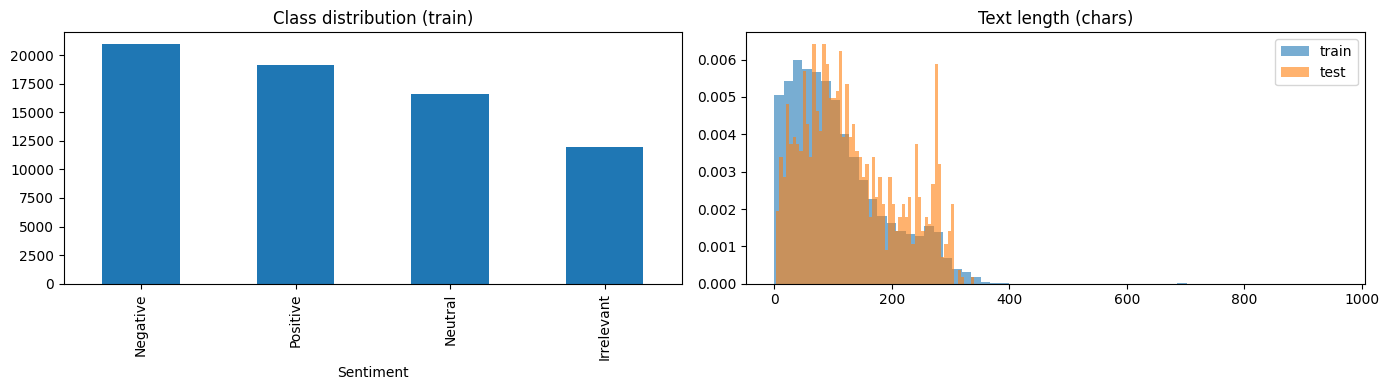

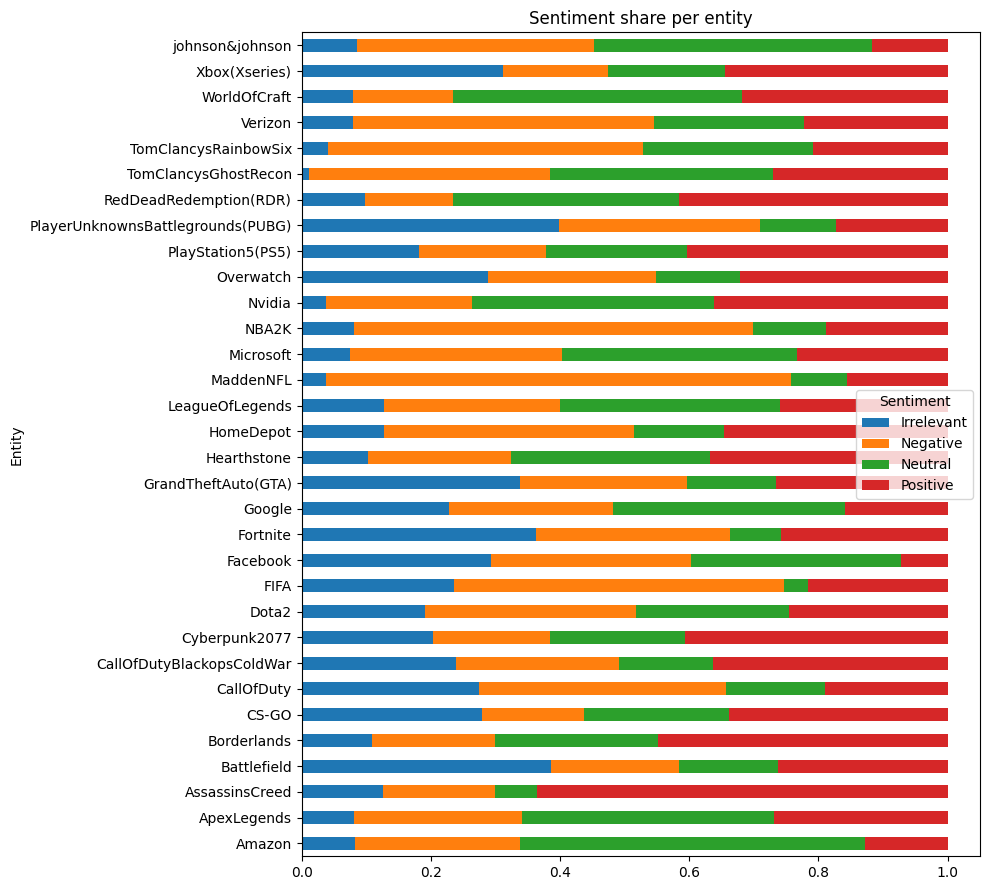

Sentiment
Negative      0.305
Positive      0.279
Neutral       0.242
Irrelevant    0.174
Name: proportion, dtype: float64


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
train.Sentiment.value_counts().plot.bar(ax=ax[0], title="Class distribution (train)")
ax[1].hist(train.Text.str.len(), bins=60, alpha=.6, density=True, label="train")
ax[1].hist(test.Text.str.len(), bins=60, alpha=.6, density=True, label="test")
ax[1].set_title("Text length (chars)"); ax[1].legend()
plt.tight_layout(); plt.show()
pd.crosstab(train.Entity, train.Sentiment, normalize="index").plot.barh(stacked=True, figsize=(10, 9),
                                                                        title="Sentiment share per entity")
plt.tight_layout(); plt.show()
print(train.Sentiment.value_counts(normalize=True).round(3))

**Structure of the training data.** Each `ID` is one original tweet (first row) plus 5 augmented variants (synonym swaps, word drops/insertions, back-translation-like rewrites, `<unk>` tokens) — always with the same label. The test IDs never occur in train and only ~1 % of test texts appear verbatim in train. Test tweets are longer and contain more emojis / URLs than the augmented rows, i.e. they look like the *original* rows.

In [4]:
grp = train.groupby("ID")
print("rows per ID:", grp.size().value_counts().to_dict())
print("IDs with >1 label:", (grp.Sentiment.nunique() > 1).sum())
print("test IDs present in train:", test.ID.isin(train.ID).sum())
print("test texts found verbatim in train: %.1f%%" % (100 * test.Text.str.strip().str.lower()
      .isin(set(train.Text.str.strip().str.lower())).mean()))
print("all test entities seen in train:", test.Entity.isin(train.Entity).all())
pos = grp.cumcount()
print("mean length — original rows: %.0f | augmented rows: %.0f | test: %.0f" % (
      train.Text[pos == 0].str.len().mean(), train.Text[pos > 0].str.len().mean(), test.Text.str.len().mean()))
for t in train[train.ID == train.ID.iloc[0]].Text: print("  ·", t)

rows per ID: {6: 11447}
IDs with >1 label: 0
test IDs present in train: 0
test texts found verbatim in train: 1.0%
all test entities seen in train: True
mean length — original rows: 107 | augmented rows: 108 | test: 132


## 2. Text cleaning (for the TF-IDF baseline)
* HTML entities (`&amp;`) unescaped; URLs (incl. truncated `bbc.co.uk/news/…`) → `URL`; mentions → `@USER`;
* emojis → their names (`🤣` → ` rolling_on_the_floor_laughing `) so word n-grams can use them;
* elongations squashed (`sooooo` → `soo`), repeated punctuation capped (`!!!!!` → `!!`), whitespace collapsed, lower-case.

The transformers get the raw text with only the standard Twitter-LM masking (`@user`, `http`); their own tokenizers handle the rest (BERTweet additionally normalises emojis itself).

In [5]:
URL_RE = re.compile(r"https?://\S+|www\.\S+|\b\S+\.(?:com|co|ly|uk|org|net|io|gg|tv|me)(?:/\S*)?")
MENTION_RE = re.compile(r"@\w+")
ELONG_RE = re.compile(r"(\w)\1{2,}")
PUNCT_RE = re.compile(r"([!?.])\1{2,}")

def clean_text(t: str) -> str:
    t = html.unescape(t)
    t = URL_RE.sub(" URL ", t)
    t = MENTION_RE.sub(" @USER ", t)
    t = emoji.demojize(t, delimiters=(" ", " "))
    t = ELONG_RE.sub(r"\1\1", t)
    t = PUNCT_RE.sub(r"\1\1", t)
    return re.sub(r"\s+", " ", t).strip().lower()

def twitter_lm_prep(t: str) -> str:   # standard preprocessing for Twitter LMs
    return " ".join("@user" if w.startswith("@") and len(w) > 1 else "http" if w.startswith("http") else w
                    for w in t.split(" "))

train["clean"] = train.Text.map(clean_text)
test["clean"] = test.Text.map(clean_text)
for raw, cl in train[["Text", "clean"]].sample(4, random_state=SEED).values:
    print("RAW  :", raw[:150]); print("CLEAN:", cl[:150]); print()

## 3. Baseline: TF-IDF + Logistic Regression, grouped 5-fold CV
Word (1,2)-gram TF-IDF (min_df=2, sublinear) ⊕ char_wb (2,5)-gram TF-IDF (min_df=3, 300k features) ⊕ entity one-hot → multinomial Logistic Regression (C=3, chosen on the same grouped CV from {1, 3, 10, 30}). Vectorisers are fit **inside each fold** on the training part only. The entity one-hot captures strong entity-specific label priors (see the per-entity plot).

Accuracy is reported on all rows and on **original tweets only** — the realistic estimate of test accuracy.

In [6]:
CLASSES = np.array(sorted(train.Sentiment.unique()))
y = train.Sentiment.values
groups = train.ID.values
is_orig = (train.groupby("ID").cumcount() == 0).values

folds = list(GroupKFold(n_splits=N_FOLDS).split(train, y, groups))
for a, b in folds:
    assert not set(groups[a]) & set(groups[b])        # no ID leaks across folds
FOLD_OF = np.empty(len(train), dtype=int)             # fold in which each row is held out
for k, (_, b) in enumerate(folds):
    FOLD_OF[b] = k

def tfidf_fit_predict(tr_df, te_df):
    w = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    c = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True, max_features=300_000)
    o = OneHotEncoder(handle_unknown="ignore")
    Xtr = hstack([w.fit_transform(tr_df.clean), c.fit_transform(tr_df.clean), o.fit_transform(tr_df[["Entity"]])]).tocsr()
    Xte = hstack([w.transform(te_df.clean), c.transform(te_df.clean), o.transform(te_df[["Entity"]])]).tocsr()
    model = LogisticRegression(C=3, max_iter=3000).fit(Xtr, tr_df.Sentiment.values)
    assert (model.classes_ == CLASSES).all()
    return model.predict_proba(Xte)

t0 = time.time()
f_oof = f"{FEAT_DIR}/tfidf_oof.npy"
if os.path.exists(f_oof):
    OOF_TFIDF = np.load(f_oof); print("loaded cache tfidf OOF")
else:
    OOF_TFIDF = np.zeros((len(train), len(CLASSES)))
    for a, b in folds:
        OOF_TFIDF[b] = tfidf_fit_predict(train.iloc[a], train.iloc[b])
    np.save(f_oof, OOF_TFIDF)
pred = CLASSES[OOF_TFIDF.argmax(1)]
print(f"TF-IDF OOF acc: all rows={accuracy_score(y, pred):.4f} | original tweets={accuracy_score(y[is_orig], pred[is_orig]):.4f}"
      f" | macro-F1 originals={f1_score(y[is_orig], pred[is_orig], average='macro'):.4f}  ({time.time()-t0:.0f}s)")

loaded cache tfidf OOF
TF-IDF OOF acc: all rows=0.5683 | original tweets=0.5862 | macro-F1 originals=0.5625  (1s)


## 4. Fine-tuning pre-trained encoders (PyTorch)
Five pre-trained **encoders** are fine-tuned end-to-end on `CAIRLAB.csv` with a hand-written PyTorch training loop. All were pre-trained **only with self-supervised objectives on unlabelled text** — they have never seen sentiment labels — so all task knowledge comes from the competition data:

| Backbone | Pre-training (self-supervised) | License |
|---|---|---|
| `cardiffnlp/twitter-roberta-base-2022-154m` | RoBERTa-base, masked LM on 154M tweets (2018-2022) | MIT |
| `vinai/bertweet-base` | RoBERTa-base architecture, masked LM on 850M tweets, tweet-normalising tokenizer | MIT |
| `cardiffnlp/twitter-roberta-large-2022-154m` | RoBERTa-large (355M), masked LM on the same 154M tweets | MIT |
| `vinai/bertweet-large` | RoBERTa-large architecture (355M), masked LM on English tweets (BERTweet corpus) | MIT |
| `microsoft/deberta-v3-large` | DeBERTa-v3-large (435M), replaced-token detection (ELECTRA-style) on general English text (Wikipedia, books, web) | MIT |

**Architecture:** encoder → first-token representation → classification head (RoBERTa: dense H→H, tanh, dropout 0.1, dense H→4; DeBERTa: pooler dense H→H + GELU, dense H→4; H = 768 for base, 1024 for large), head randomly initialised.
**Input:** sentence pair `(Entity, Text)`, so the model knows *which* entity the sentiment is about.

**Training details / hyper-parameters**

| | |
|---|---|
| training examples | the **original** tweet of every training ID (augmented copies are often damaged paraphrases; a pilot with 1-2 copies per ID gave no gain, −0.1…−0.3 pt) |
| loss | cross-entropy with **label smoothing 0.1** (the labels are noisy) |
| optimiser | AdamW, weight decay 0.01, gradient clipping 1.0; fp16 mixed precision with gradient scaling on GPU |
| schedule | linear warm-up over the first 10 % of steps, then linear decay to 0; 3 epochs; length-bucketed dynamic padding, max_len 96 tokens |
| v2 runs | lr 3e-5 (base) / 1.5e-5 (large), batch 32, embeddings + lower 4 of 12 (large: 8 of 24) layers frozen |
| `ft_deberta_large` | lr 1e-5, batch 16, all 24 encoder layers trained (embeddings frozen) |
| seed | 42 (model init, dropout, batch order); a run whose hold-out accuracy is below 0.5 (diverged to one class) would be repeated once with seed 43 |

**Validation protocol:** one model per GroupKFold fold (5 per configuration) → out-of-fold predictions for **all** original tweets; test prediction = mean of the 5 fold models. Every finished run is cached in `FEAT_DIR` (Google Drive), so an interrupted session continues where it stopped.

In [7]:
EPOCHS = 3
train["y"] = train.Sentiment.map({c: i for i, c in enumerate(CLASSES)}).values
train["pos"] = train.groupby("ID").cumcount()

def param_groups(model, lr, llrd):
    """llrd=None → one group with every trainable parameter (v2 behaviour). Otherwise layer-wise lr decay: the head and
    the top encoder layer get `lr`, each lower layer `lr * llrd**depth`, everything below the layers the lowest lr."""
    trainable = lambda params: [p for p in params if p.requires_grad]
    if llrd is None:
        return [{"params": trainable(model.parameters()), "lr": lr}]
    base = model.base_model
    layers = base.encoder.layer; n = len(layers)
    in_base = {id(p) for p in base.parameters()}
    groups = [{"params": trainable(p for p in model.parameters() if id(p) not in in_base), "lr": lr}]   # head
    groups += [{"params": trainable(layers[i].parameters()), "lr": lr * llrd ** (n - 1 - i)} for i in range(n)]
    seen = {id(p) for g in groups for p in g["params"]}
    groups.append({"params": [p for p in trainable(base.parameters()) if id(p) not in seen], "lr": lr * llrd ** n})
    return [g for g in groups if g["params"]]

def finetune(model_name, tag, fold, epochs=EPOCHS, bs=32, lr=3e-5, freeze=4, llrd=None, max_len=96, smoothing=0.1,
             n_aug=0, seed=SEED, retry=True):
    """fold >= 0: train on the other folds, predict the original tweets of `fold` + test. fold = -1: train on all data.
    freeze: number of lower encoder layers frozen (embeddings are always frozen). llrd: layer-wise lr decay (None = off).
    n_aug: number of augmented copies per training ID used in addition to the original tweet (0 = originals only).
    Returns None when ONLY_CACHED is set and the run is not in the cache."""
    run_args = dict(model_name=model_name, tag=tag, fold=fold, epochs=epochs, bs=bs, lr=lr, freeze=freeze, llrd=llrd,
                    max_len=max_len, smoothing=smoothing, n_aug=n_aug)
    suffix = f"fold{fold}" if fold >= 0 else "full"
    if n_aug: tag = f"{tag}_aug{n_aug}"
    f_test = f"{FEAT_DIR}/{tag}_{suffix}_test.npy"
    f_val, f_rows = f"{FEAT_DIR}/{tag}_{suffix}_valid.npy", f"{FEAT_DIR}/{tag}_{suffix}_valid_rows.npy"
    if os.path.exists(f_test) and (fold < 0 or (os.path.exists(f_val) and os.path.exists(f_rows))):
        print(f"loaded cache {tag} {suffix}")
        return (np.load(f_val), np.load(f_rows)) if fold >= 0 else (None, None), np.load(f_test)
    if ONLY_CACHED:
        return None

    seed_everything(seed)
    tr_rows, va_rows = folds[fold] if fold >= 0 else (np.arange(len(train)), np.array([], dtype=int))
    tr_df = train.iloc[tr_rows]; tr_df = tr_df[tr_df.pos <= n_aug]
    va_df = train.iloc[va_rows]; va_df = va_df[va_df.pos == 0]
    print(f"[{tag} {suffix}] train rows {len(tr_df)} | valid (original tweets) {len(va_df)}", flush=True)

    tok = AutoTokenizer.from_pretrained(model_name, **({"normalization": True} if "bertweet" in model_name else {}))
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=len(CLASSES)).float().to(DEVICE)  # DeBERTa-v3 checkpoint is stored in fp16 → train in fp32 + AMP
    base = model.base_model
    for prm in base.embeddings.parameters(): prm.requires_grad = False
    for layer in base.encoder.layer[:freeze]:
        for prm in layer.parameters(): prm.requires_grad = False

    def encode(df):
        if len(df) == 0: return []
        return tok(df.Entity.tolist(), [twitter_lm_prep(t) for t in df.Text], truncation=True, max_length=max_len)["input_ids"]

    def batches(ids, order, size):
        for i in range(0, len(order), size):
            idx = order[i:i + size]
            L = max(len(ids[j]) for j in idx)
            x = torch.full((len(idx), L), tok.pad_token_id, dtype=torch.long)
            for r, j in enumerate(idx): x[r, :len(ids[j])] = torch.tensor(ids[j])
            yield idx, x.to(DEVICE), (x != tok.pad_token_id).long().to(DEVICE)

    def bucket_order(ids, rng, size, chunk=50):   # shuffle, sort by length inside chunks, shuffle batches
        perm = rng.permutation(len(ids)); out = []
        for c in range(0, len(perm), size * chunk):
            part = sorted(perm[c:c + size * chunk], key=lambda j: len(ids[j]))
            out += [part[i:i + size] for i in range(0, len(part), size)]
        rng.shuffle(out)
        return [j for b in out for j in b]

    @torch.inference_mode()
    def predict(ids):
        model.eval(); P = np.zeros((len(ids), len(CLASSES)), dtype=np.float32)
        order = np.argsort([len(x) for x in ids], kind="stable")
        for idx, x, m in batches(ids, order, 64):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                logits = model(input_ids=x, attention_mask=m).logits
            P[idx] = torch.softmax(logits.float(), -1).cpu().numpy()
        return P

    tr_ids, va_ids, te_ids = encode(tr_df), encode(va_df), encode(test)
    ytr = torch.tensor(tr_df.y.values)
    opt = torch.optim.AdamW(param_groups(model, lr, llrd), lr=lr, weight_decay=0.01)
    steps = epochs * ((len(tr_ids) + bs - 1) // bs)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    loss_fn = torch.nn.CrossEntropyLoss(label_smoothing=smoothing)
    use_amp = DEVICE.type == "cuda"                              # fp16 mixed precision on GPU only (no-op on CPU)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=use_amp)
    rng = np.random.RandomState(seed)
    t0 = time.time()
    for ep in range(epochs):
        model.train(); tot = n = 0
        for idx, x, m in batches(tr_ids, bucket_order(tr_ids, rng, bs), bs):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                logits = model(input_ids=x, attention_mask=m).logits
            loss = loss_fn(logits.float(), ytr[idx].to(DEVICE))
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad()
            tot += loss.item() * len(idx); n += len(idx)
        msg = f"  epoch {ep} train_loss {tot/n:.4f} {time.time()-t0:.0f}s"
        if len(va_ids):
            Pva = predict(va_ids); msg += f" | hold-out acc (original tweets) {(Pva.argmax(1) == va_df.y.values).mean():.4f}"
        print(msg, flush=True)
    diverged = fold >= 0 and (Pva.argmax(1) == va_df.y.values).mean() < 0.5
    if not diverged or not retry:
        Pte = predict(te_ids); np.save(f_test, Pte)
        if fold >= 0:
            np.save(f_val, Pva); np.save(f_rows, va_df.index.values)
    del model, opt
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    if diverged and retry:
        print(f"  run diverged (hold-out acc < 0.5) — repeating once with seed {seed + 1}", flush=True)
        return finetune(**run_args, seed=seed + 1, retry=False)
    return ((Pva, va_df.index.values) if fold >= 0 else (None, None)), Pte

In [8]:
FT_MODELS = {   # tag: backbone + hyper-parameters. The first four are the v2 runs (unchanged → loaded from the cache).
    "ft_tw2022":              dict(model_name="cardiffnlp/twitter-roberta-base-2022-154m", lr=3e-5, freeze=4),
    "ft_bertweet":            dict(model_name="vinai/bertweet-base", lr=3e-5, freeze=4),
    "ft_tw2022_large":        dict(model_name="cardiffnlp/twitter-roberta-large-2022-154m", lr=1.5e-5, freeze=8),
    "ft_bertweet_large":      dict(model_name="vinai/bertweet-large", lr=1.5e-5, freeze=8),
    # different pre-training objective and corpus → different errors
    "ft_deberta_large":       dict(model_name="microsoft/deberta-v3-large", lr=1e-5, freeze=0, bs=16),
}
FT_OOF, FT_TEST = {}, {}
for tag, cfg in FT_MODELS.items():
    oof, te, complete = np.zeros((len(train), len(CLASSES))), np.zeros((len(test), len(CLASSES))), True
    for k in range(N_FOLDS):
        out = finetune(tag=tag, fold=k, **cfg)
        if out is None:
            complete = False; break
        (Pva, rows), Pte = out
        oof[rows] = Pva
        te += Pte / N_FOLDS                                   # mean of the 5 fold models
    if not complete:
        print(f"{tag:24s} not in the cache (ONLY_CACHED) — left out of the ensemble"); continue
    FT_OOF[tag], FT_TEST[tag] = oof, te
    p = CLASSES[oof[is_orig].argmax(1)]
    print(f"{tag:24s} OOF acc (all original tweets) = {accuracy_score(y[is_orig], p):.4f}")

HOLD_ROWS = np.where(is_orig)[0]                          # selection set: every original tweet (out-of-fold)
HOLD = {"tfidf": OOF_TFIDF[HOLD_ROWS]} | {t: FT_OOF[t][HOLD_ROWS] for t in FT_OOF}

loaded cache ft_tw2022 fold0
loaded cache ft_tw2022 fold1
loaded cache ft_tw2022 fold2
loaded cache ft_tw2022 fold3
loaded cache ft_tw2022 fold4
ft_tw2022                OOF acc (all original tweets) = 0.6820
loaded cache ft_bertweet fold0
loaded cache ft_bertweet fold1
loaded cache ft_bertweet fold2
loaded cache ft_bertweet fold3
loaded cache ft_bertweet fold4
ft_bertweet              OOF acc (all original tweets) = 0.6818
loaded cache ft_tw2022_large fold0
loaded cache ft_tw2022_large fold1
loaded cache ft_tw2022_large fold2
loaded cache ft_tw2022_large fold3
loaded cache ft_tw2022_large fold4
ft_tw2022_large          OOF acc (all original tweets) = 0.7015
loaded cache ft_bertweet_large fold0
loaded cache ft_bertweet_large fold1
loaded cache ft_bertweet_large fold2
loaded cache ft_bertweet_large fold3
loaded cache ft_bertweet_large fold4
ft_bertweet_large        OOF acc (all original tweets) = 0.6998
loaded cache ft_deberta_large fold0
loaded cache ft_deberta_large fold1
loaded cache

## 5. Choosing the ensemble
Selection set: all 11,447 original tweets (out-of-fold) — none of the models was trained on them. Three kinds of candidates:
* **fixed blends** (no fitted parameters, so their out-of-fold accuracy is already an honest estimate): the v2 final blend `0.8·mean(v2 large) + 0.2·tfidf`, and `a·mean(models) + (1−a)·tfidf` with a ∈ {1.0, 0.9, 0.8} over all fine-tuned models and over all large models;
* **weighted average** — one weight per model on the simplex, fitted by minimising log-loss;
* **stacking** — multinomial logistic regression on all models' log-probabilities + entity one-hot.

The fitted candidates are scored with **nested cross-validation** on the same GroupKFold folds: weights / stacker fitted on the out-of-fold predictions of 4 folds, accuracy measured on the 5th. The candidate with the best accuracy is chosen; among candidates within 0.1 pt of the best one the simplest is taken (differences that small are selection noise — the standard error of an accuracy on 11k tweets is ≈0.4 pt). The test set is never used for any decision.

In [9]:
y_hold = train.y.values[HOLD_ROWS]
fold_hold = FOLD_OF[HOLD_ROWS]
NAMES = list(HOLD)
acc = lambda P: (P.argmax(1) == y_hold).mean()
mean_of = lambda P, tags: sum(P[t] for t in tags) / len(tags)

# (a) fixed blends
FIXED = {}
V2_FINAL, V2_LARGE = "v2 final: 0.8*mean(v2 large) + 0.2*tfidf", ["ft_tw2022_large", "ft_bertweet_large"]
if all(t in HOLD for t in V2_LARGE):
    FIXED[V2_FINAL] = lambda P: 0.8 * mean_of(P, V2_LARGE) + 0.2 * P["tfidf"]
SUBSETS = {"all fine-tuned": [t for t in NAMES if t != "tfidf"], "all large": [t for t in NAMES if "large" in t]}
for sname, tags in SUBSETS.items():
    for a in (1.0, 0.9, 0.8):
        if tags:
            FIXED[f"{a:.1f}*mean({sname}) + {1 - a:.1f}*tfidf"] = lambda P, tags=tags, a=a: a * mean_of(P, tags) + (1 - a) * P["tfidf"]

# (b) weighted average, weights on the simplex (softmax parametrisation) fitted by minimising log-loss
def fit_weights(P, yy):
    X = np.stack([P[n] for n in NAMES])
    def loss(z):
        w = np.exp(z - z.max()); w /= w.sum()
        return -np.log(np.tensordot(w, X, 1)[np.arange(len(yy)), yy] + 1e-12).mean()
    z = minimize(loss, np.zeros(len(NAMES)), method="L-BFGS-B").x
    w = np.exp(z - z.max())
    return dict(zip(NAMES, w / w.sum()))
weighted = lambda P, w: sum(w[n] * P[n] for n in NAMES)

# (c) stacking: multinomial logistic regression on log-probabilities + entity one-hot
ENT_OHE = OneHotEncoder(handle_unknown="ignore").fit(train[["Entity"]])
def stack_features(P, entities):
    return hstack([np.log(np.clip(np.hstack([P[n] for n in NAMES]), 1e-6, 1)), ENT_OHE.transform(entities)]).tocsr()
X_HOLD = stack_features(HOLD, train.iloc[HOLD_ROWS][["Entity"]])
stacker = lambda: LogisticRegression(C=1.0, max_iter=3000)

# nested CV for the fitted candidates: fit on the out-of-fold predictions of 4 folds, predict the 5th
NESTED = {"weighted": np.zeros_like(HOLD["tfidf"]), "stacking": np.zeros_like(HOLD["tfidf"])}
for k in range(N_FOLDS):
    fit, ev = fold_hold != k, fold_hold == k
    w = fit_weights({n: HOLD[n][fit] for n in NAMES}, y_hold[fit])
    NESTED["weighted"][ev] = weighted({n: HOLD[n][ev] for n in NAMES}, w)
    NESTED["stacking"][ev] = stacker().fit(X_HOLD[fit], y_hold[fit]).predict_proba(X_HOLD[ev])

CANDIDATES = {name: (0, f(HOLD)) for name, f in FIXED.items()}     # name: (complexity, out-of-fold probabilities)
CANDIDATES["weighted average (fitted, nested CV)"] = (1, NESTED["weighted"])
CANDIDATES["stacking LR (fitted, nested CV)"] = (2, NESTED["stacking"])
singles = pd.Series({f"single: {n}": acc(HOLD[n]) for n in NAMES})
res = pd.DataFrame({"accuracy": {n: acc(P) for n, (c, P) in CANDIDATES.items()},
                    "complexity": {n: c for n, (c, P) in CANDIDATES.items()}})
display(singles.sort_values(ascending=False).round(4).to_frame("accuracy (original tweets)"))
display(res.sort_values("accuracy", ascending=False).round(4))

near_best = res[res.accuracy >= res.accuracy.max() - 0.001]
BEST = near_best.sort_values(["complexity", "accuracy"], ascending=[True, False]).index[0]
BEST_OOF = CANDIDATES[BEST][1]
print("chosen scheme:", BEST, f"| out-of-fold accuracy {acc(BEST_OOF):.4f}")
if V2_FINAL in CANDIDATES:
    d = (BEST_OOF.argmax(1) == y_hold).astype(float) - (CANDIDATES[V2_FINAL][1].argmax(1) == y_hold)
    print(f"gain over the v2 final blend: {100 * d.mean():+.2f} pt ± {100 * d.std() / np.sqrt(len(d)):.2f} (paired s.e.)")

pred = CLASSES[BEST_OOF.argmax(1)]
print(classification_report(CLASSES[y_hold], pred, digits=4))
pd.DataFrame(confusion_matrix(CLASSES[y_hold], pred, labels=CLASSES), index=CLASSES, columns=CLASSES)

,accuracy (original tweets)
single: ft_tw2022_large,0.7015
single: ft_deberta_large,0.7004
single: ft_bertweet_large,0.6998
single: ft_tw2022,0.6820
single: ft_bertweet,0.6818
single: tfidf,0.5862


,accuracy,complexity
"weighted average (fitted, nested CV)",0.7156,1
0.9*mean(all large) + 0.1*tfidf,0.7153,0
1.0*mean(all large) + 0.0*tfidf,0.7149,0
"stacking LR (fitted, nested CV)",0.7147,2
0.8*mean(all large) + 0.2*tfidf,0.7129,0
0.9*mean(all fine-tuned) + 0.1*tfidf,0.7118,0
1.0*mean(all fine-tuned) + 0.0*tfidf,0.7108,0
v2 final: 0.8*mean(v2 large) + 0.2*tfidf,0.7095,0
0.8*mean(all fine-tuned) + 0.2*tfidf,0.7092,0


chosen scheme: 0.9*mean(all large) + 0.1*tfidf | out-of-fold accuracy 0.7153
gain over the v2 final blend: +0.58 pt ± 0.21 (paired s.e.)
              precision    recall  f1-score   support

  Irrelevant     0.6301    0.5394    0.5812      1993
    Negative     0.7675    0.8244    0.7949      3491
     Neutral     0.6998    0.6163    0.6554      2768
    Positive     0.7118    0.7915    0.7496      3195

    accuracy                         0.7153     11447
   macro avg     0.7023    0.6929    0.6953     11447
weighted avg     0.7116    0.7153    0.7113     11447



,Irrelevant,Negative,Neutral,Positive
Irrelevant,1075,314,244,360
Negative,190,2878,211,212
Neutral,251,359,1706,452
Positive,190,199,277,2529


### 5b. Where the remaining errors are
Accuracy of the chosen blend by confidence decile (out-of-fold, original tweets). A well-calibrated model with almost error-free top deciles and ~coin-flip bottom deciles means the remaining errors are concentrated in tweets that are genuinely ambiguous or mislabelled — e.g. empty tweets, whose labels are close to random.

In [10]:
conf, correct = BEST_OOF.max(1), BEST_OOF.argmax(1) == y_hold
by_conf = pd.DataFrame({"confidence": conf, "correct": correct, "decile": pd.qcut(conf, 10, labels=False, duplicates="drop")})
display(by_conf.groupby("decile").agg(mean_confidence=("confidence", "mean"), accuracy=("correct", "mean"), n=("correct", "size")).round(3))
empty = np.array([len(t.strip()) <= 2 for t in train.Text.values[HOLD_ROWS]])
print(f"empty original tweets: {empty.sum()} | labels: {pd.Series(CLASSES[y_hold[empty]]).value_counts().to_dict()}"
      f" | accuracy on them: {correct[empty].mean():.3f}")

,mean_confidence,accuracy,n
decile,,,
0,0.401,0.389,1145
1,0.498,0.491,1145
2,0.576,0.540,1144
3,0.655,0.614,1145
4,0.731,0.689,1145
5,0.794,0.770,1144
6,0.842,0.851,1145
7,0.881,0.881,1144
8,0.915,0.947,1145


empty original tweets: 172 | labels: {'Neutral': 58, 'Negative': 45, 'Positive': 36, 'Irrelevant': 33} | accuracy on them: 0.430


## 6. Refit the baseline on all training data, apply the chosen scheme to the test set, write `submission.csv`

In [11]:
f_te = f"{FEAT_DIR}/tfidf_full_test.npy"
if os.path.exists(f_te):
    P_TFIDF_TEST = np.load(f_te); print("loaded cache tfidf test")
else:
    t0 = time.time(); P_TFIDF_TEST = tfidf_fit_predict(train, test); np.save(f_te, P_TFIDF_TEST)
    print(f"TF-IDF refit on full train ({time.time()-t0:.0f}s)")
TEST_P = {"tfidf": P_TFIDF_TEST} | FT_TEST

complexity = CANDIDATES[BEST][0]
if complexity == 0:
    final_test = FIXED[BEST](TEST_P)
elif complexity == 1:
    W = fit_weights(HOLD, y_hold)                             # refit on all out-of-fold predictions
    print("blend weights:", {n: round(float(v), 3) for n, v in W.items()})
    final_test = weighted(TEST_P, W)
else:
    final_test = stacker().fit(X_HOLD, y_hold).predict_proba(stack_features(TEST_P, test[["Entity"]]))
test_pred = CLASSES[final_test.argmax(1)]
if V2_FINAL in FIXED:
    print(f"test predictions that differ from the v2 final blend: {(test_pred != CLASSES[FIXED[V2_FINAL](TEST_P).argmax(1)]).mean():.1%}")

ENC_TEST = final_test                                         # encoder-blend test probabilities (used again in §6b)
sub_enc = pd.DataFrame({"ID": test.ID.values, "Sentiment": test_pred})
assert len(sub_enc) == len(test) and sub_enc.ID.equals(test.ID) and set(sub_enc.Sentiment) <= set(CLASSES)
sub_enc.to_csv("submission_encoders.csv", index=False)
print(sub_enc.Sentiment.value_counts(normalize=True).round(3))
if IN_COLAB:
    from google.colab import files; files.download("submission_encoders.csv")
sub_enc.head()

loaded cache tfidf test
test predictions that differ from the v2 final blend: 5.4%
Sentiment
Positive      0.324
Negative      0.304
Neutral       0.230
Irrelevant    0.142
Name: proportion, dtype: float64


## 6b. Fine-tuned LLM classifier (QLoRA)
**Why.** About a fifth of the encoder errors need world knowledge, sarcasm detection or working out *which* entity the sentiment is aimed at. A much larger pre-trained backbone is the most direct way to address them.

**Allowed by the organiser.** Fine-tuning a base open LLM on the competition data as a classifier was confirmed as allowed under rule 6b by the competition host (11 Oct 2026).

**Model.** `Qwen/Qwen2.5-7B` — the **base** model (next-token-prediction pre-training only; *not* the instruction-tuned / chat version), Apache-2.0. It is **not used zero-shot and never prompted**: it is turned into a sequence classifier and trained on `CAIRLAB.csv` exactly like the encoders above.

**Architecture.** Input `"{Entity}: {Text}"` (same Twitter preprocessing as the encoders) → Qwen2.5-7B decoder → hidden state of the last token → linear classification head (3584 → 4, trained in fp32). **Two runs, averaged.** Run 1: randomly initialised head, 1 epoch — Qwen's last hidden states have a large norm, so the random head starts with logits of ±10 (loss 4.4), a quarter of the epoch is spent recovering, hold-out accuracy 0.677; even so it adds +1.3 pt to the encoder blend because its errors are very different. Run 2: the head is **initialised to zero** (uniform start, loss 1.39) and trained for 2 epochs. Run 3 repeats run 2 with another seed (2026). The LLM prediction is the mean of the runs' probabilities.

**QLoRA, written by hand.** The 7B weights are frozen and stored in 4-bit NF4 (bitsandbytes) so the model fits a 16 GB T4. Every attention (q, k, v, o) and MLP (gate, up, down) projection of all 28 layers gets a trainable low-rank adapter `W x + (α/r)·B·A·dropout(x)` (r = 16, α = 32, dropout 0.05; B initialised to 0, so training starts from the pre-trained model) — ≈ 40M trainable parameters + the head.

| | |
|---|---|
| training examples | original tweets of folds 1-4 (same GroupKFold as above); fold 0 (2,290 original tweets) is the hold-out |
| loss / optimiser | cross-entropy with label smoothing 0.1; AdamW (lr 1e-4, no weight decay), gradient clipping 1.0, fp16 autocast + gradient scaling |
| schedule | run 1: 1 epoch, run 2: 2 epochs; batch 16, linear warm-up 10 % then linear decay; length-bucketed dynamic padding, max_len 128 tokens; gradient checkpointing |
| test prediction | mean of the three runs (trained on folds 1-4) and of run 2's recipe retrained on **all** 11,447 original tweets (+25 % data); the mixing weight a is the one chosen on fold 0 |

**Blending, decided on the hold-out only.** `final = (1−a)·encoder blend + a·LLM` with a ∈ {0, 0.2, …, 0.8, 1}. To get an *honest* estimate, the fold-0 tweets are split in two halves by ID: a is chosen on one half and scored on the other, and vice versa. The LLM is used only if this honest gain is ≥ 0.5 pt; otherwise `submission.csv` equals the encoder submission.

In [12]:
LLM_NAME, LLM_FOLD = "Qwen/Qwen2.5-7B", 0
LLM_CFG = dict(r=16, alpha=32, dropout=0.05, lr=1e-4, bs=16, max_len=128, smoothing=0.1)
LLM_RUNS = {   # tag: run-specific settings; the LLM prediction is the mean of the runs
    "llm_qwen25_7b":    dict(epochs=1, zero_head=False),   # first run: randomly initialised head, 1 epoch
    "llm_qwen25_7b_v2": dict(epochs=2, zero_head=True),    # second run: zero-initialised head, 2 epochs
    "llm_qwen25_7b_v3": dict(epochs=2, zero_head=True, seed=2026),   # third run: run-2 recipe, different seed
}

class LoRALinear(torch.nn.Module):   # frozen (4-bit) linear layer + trainable low-rank update: y = W x + (alpha/r)·B(A(dropout(x)))
    def __init__(self, base, r, alpha, dropout):
        super().__init__()
        dev = next(base.parameters()).device
        self.base, self.scale, self.drop = base, alpha / r, torch.nn.Dropout(dropout)
        self.A = torch.nn.Linear(base.in_features, r, bias=False, device=dev, dtype=torch.float32)
        self.B = torch.nn.Linear(r, base.out_features, bias=False, device=dev, dtype=torch.float32)
        torch.nn.init.kaiming_uniform_(self.A.weight, a=5 ** 0.5)
        torch.nn.init.zeros_(self.B.weight)                      # adapter starts as a no-op
    def forward(self, x):
        return self.base(x) + self.B(self.A(self.drop(x))) * self.scale

def llm_finetune(fold, tag, model_name=LLM_NAME, r=16, alpha=32, dropout=0.05, lr=1e-4, epochs=1, bs=16,
                 max_len=128, smoothing=0.1, zero_head=True, seed=SEED):
    # fold >= 0: train on the original tweets of the other folds, predict the original tweets of `fold` + test.
    # fold = -1: train on all original tweets, predict test only. Results are cached in FEAT_DIR.
    suffix = f"fold{fold}" if fold >= 0 else "full"
    f_test, f_val, f_rows = (f"{FEAT_DIR}/{tag}_{suffix}_{s}.npy" for s in ("test", "valid", "valid_rows"))
    if os.path.exists(f_test) and (fold < 0 or (os.path.exists(f_val) and os.path.exists(f_rows))):
        print(f"loaded cache {tag} {suffix}")
        return ((np.load(f_val), np.load(f_rows)) if fold >= 0 else (None, None)), np.load(f_test)
    if ONLY_CACHED:
        return None
    seed_everything(seed)
    tr_rows, va_rows = folds[fold] if fold >= 0 else (np.arange(len(train)), np.array([], dtype=int))
    tr_df = train.iloc[tr_rows]; tr_df = tr_df[tr_df.pos == 0]
    va_df = train.iloc[va_rows]; va_df = va_df[va_df.pos == 0]
    print(f"[{tag} {suffix}] train (original tweets) {len(tr_df)} | hold-out {len(va_df)}", flush=True)

    tok = AutoTokenizer.from_pretrained(model_name)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    load_kw = {}
    if DEVICE.type == "cuda":
        from transformers import BitsAndBytesConfig
        load_kw = dict(quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                              bnb_4bit_use_double_quant=True,
                                                              bnb_4bit_compute_dtype=torch.float16),
                       dtype=torch.float16, device_map={"": 0})
    t0 = time.time()
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=len(CLASSES), **load_kw)
    model.config.pad_token_id = tok.pad_token_id                 # the head reads the last non-padding token
    model.config.use_cache = False
    for prm in model.parameters(): prm.requires_grad = False
    for layer in model.model.layers:
        for block, names in ((layer.self_attn, ("q_proj", "k_proj", "v_proj", "o_proj")),
                             (layer.mlp, ("gate_proj", "up_proj", "down_proj"))):
            for n in names:
                setattr(block, n, LoRALinear(getattr(block, n), r, alpha, dropout))
    model.score.float().requires_grad_(True)                     # classification head, trained in fp32
    if zero_head:
        torch.nn.init.zeros_(model.score.weight)                 # start from uniform predictions (random head → huge logits)
    if DEVICE.type == "cuda":
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    else:
        model.to(DEVICE)
    trainable = [q for q in model.parameters() if q.requires_grad]
    print(f"  loaded in {time.time()-t0:.0f}s | trainable parameters {sum(q.numel() for q in trainable)/1e6:.1f}M", flush=True)

    def encode(df):
        if len(df) == 0: return []
        texts = [f"{e}: {twitter_lm_prep(t)}" for e, t in zip(df.Entity, df.Text)]
        return tok(texts, truncation=True, max_length=max_len, add_special_tokens=False)["input_ids"]

    def batches(ids, order, size):
        for i in range(0, len(order), size):
            idx = order[i:i + size]
            L = max(len(ids[j]) for j in idx)
            x = torch.full((len(idx), L), tok.pad_token_id, dtype=torch.long)
            m = torch.zeros((len(idx), L), dtype=torch.long)
            for row, j in enumerate(idx):
                x[row, :len(ids[j])] = torch.tensor(ids[j]); m[row, :len(ids[j])] = 1
            yield idx, x.to(DEVICE), m.to(DEVICE)

    def bucket_order(ids, rng, size, chunk=50):
        perm = rng.permutation(len(ids)); out = []
        for c in range(0, len(perm), size * chunk):
            part = sorted(perm[c:c + size * chunk], key=lambda j: len(ids[j]))
            out += [part[i:i + size] for i in range(0, len(part), size)]
        rng.shuffle(out)
        return [j for b in out for j in b]

    use_amp = DEVICE.type == "cuda"
    @torch.inference_mode()
    def predict(ids):
        model.eval(); P = np.zeros((len(ids), len(CLASSES)), dtype=np.float32)
        for idx, x, m in batches(ids, np.argsort([len(v) for v in ids], kind="stable"), 32):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                logits = model(input_ids=x, attention_mask=m).logits
            P[idx] = torch.softmax(logits.float(), -1).cpu().numpy()
        return P

    tr_ids, va_ids, te_ids = encode(tr_df), encode(va_df), encode(test)
    ytr = torch.tensor(tr_df.y.values)
    opt = torch.optim.AdamW(trainable, lr=lr, weight_decay=0.0)
    steps = epochs * ((len(tr_ids) + bs - 1) // bs)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    loss_fn = torch.nn.CrossEntropyLoss(label_smoothing=smoothing)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=use_amp)
    rng = np.random.RandomState(seed)
    t0 = time.time(); step = 0
    for ep in range(epochs):
        model.train(); tot = n = 0
        for idx, x, m in batches(tr_ids, bucket_order(tr_ids, rng, bs), bs):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                logits = model(input_ids=x, attention_mask=m).logits
            loss = loss_fn(logits.float(), ytr[idx].to(DEVICE))
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(trainable, 1.0)
            scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
            tot += loss.item() * len(idx); n += len(idx); step += 1
            if step % 50 == 0 or step == steps:
                el = time.time() - t0
                print(f"  step {step}/{steps} loss {tot/n:.4f} | {el/60:.1f} min, ETA {el/step*(steps-step)/60:.1f} min", flush=True)
    if fold >= 0:
        Pva = predict(va_ids)
        print(f"  hold-out acc (fold {fold} original tweets) {(Pva.argmax(1) == va_df.y.values).mean():.4f} | {(time.time()-t0)/60:.1f} min", flush=True)
        np.save(f_val, Pva); np.save(f_rows, va_df.index.values)
    Pte = predict(te_ids); np.save(f_test, Pte)
    del model, opt
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return ((Pva, va_df.index.values) if fold >= 0 else (None, None)), Pte

LLM_FULL_REFIT = "llm_qwen25_7b_v2"   # if the LLM is used: retrain this run's recipe on all original tweets (None = off)
LLM_OUTS = {tag: llm_finetune(LLM_FOLD, tag=tag, **(LLM_CFG | cfg)) for tag, cfg in LLM_RUNS.items()}
LLM_OUTS = {tag: out for tag, out in LLM_OUTS.items() if out is not None}     # ONLY_CACHED may skip unfinished runs

loaded cache llm_qwen25_7b fold0
loaded cache llm_qwen25_7b_v2 fold0
loaded cache llm_qwen25_7b_v3 fold0


In [13]:
final_test_all, ALPHA = ENC_TEST, 0.0
if not LLM_OUTS:
    print("no LLM run available (ONLY_CACHED) — submission.csv = encoder submission")
else:
    llm_rows = next(iter(LLM_OUTS.values()))[0][1]
    assert all((out[0][1] == llm_rows).all() for out in LLM_OUTS.values())
    P_llm_va = np.mean([out[0][0] for out in LLM_OUTS.values()], axis=0)        # mean of the LLM runs
    P_llm_te = np.mean([out[1] for out in LLM_OUTS.values()], axis=0)
    where = pd.Series(np.arange(len(HOLD_ROWS)), index=HOLD_ROWS)[llm_rows].values    # positions inside HOLD
    yv, enc_va = y_hold[where], BEST_OOF[where]
    single = {f"LLM mean of {len(LLM_OUTS)} run(s)": (P_llm_va.argmax(1) == yv).mean(), "encoder blend": (enc_va.argmax(1) == yv).mean()}
    single |= {f"LLM run: {tag}": (out[0][0].argmax(1) == yv).mean() for tag, out in LLM_OUTS.items()}
    single |= {f"single: {n}": (HOLD[n][where].argmax(1) == yv).mean() for n in NAMES}
    display(pd.Series(single).sort_values(ascending=False).round(4).to_frame(f"accuracy on fold {LLM_FOLD} (original tweets)"))

    ALPHAS = np.round(np.arange(0, 1.01, 0.1), 1)
    mix = lambda a, idx: (1 - a) * enc_va[idx] + a * P_llm_va[idx]
    acc_a = lambda a, idx: (mix(a, idx).argmax(1) == yv[idx]).mean()
    curve = pd.Series({a: acc_a(a, slice(None)) for a in ALPHAS})
    display(curve.round(4).to_frame("fold-0 accuracy of (1-a)*encoders + a*LLM"))
    # honest estimate: choose a on one half of the fold-0 IDs, score on the other half (and vice versa)
    half = (train.ID.values[llm_rows] % 2 == 0)
    honest = []
    for pick, ev in ((half, ~half), (~half, half)):
        a_star = max(ALPHAS, key=lambda a: (acc_a(a, pick), -a))
        honest.append(((mix(a_star, ev).argmax(1) == yv[ev]).astype(float) - (enc_va[ev].argmax(1) == yv[ev])))
    d = np.concatenate(honest)
    gain, se = 100 * d.mean(), 100 * d.std() / np.sqrt(len(d))
    print(f"honest gain of adding the LLM (a chosen on the other half): {gain:+.2f} pt ± {se:.2f}")
    if gain >= 0.5:
        ALPHA = float(max(ALPHAS, key=lambda a: (curve[a], -a)))
        if LLM_FULL_REFIT:
            out_full = llm_finetune(-1, tag=LLM_FULL_REFIT, **(LLM_CFG | LLM_RUNS[LLM_FULL_REFIT]))
            if out_full is not None:
                P_llm_te = np.mean([out[1] for out in LLM_OUTS.values()] + [out_full[1]], axis=0)
                print(f"LLM test prediction = mean of {len(LLM_OUTS)} fold-{LLM_FOLD} runs + the {LLM_FULL_REFIT} recipe retrained on all original tweets")
        final_test_all = (1 - ALPHA) * ENC_TEST + ALPHA * P_llm_te
        print(f"→ LLM used with a = {ALPHA} (fold-0 accuracy {curve[ALPHA]:.4f} vs. encoders {curve[0.0]:.4f})")
    else:
        print("→ gain below 0.5 pt — LLM not used, submission.csv = encoder submission")

submission = pd.DataFrame({"ID": test.ID.values, "Sentiment": CLASSES[final_test_all.argmax(1)]})
assert len(submission) == len(test) and submission.ID.equals(test.ID) and set(submission.Sentiment) <= set(CLASSES)
submission.to_csv("submission.csv", index=False)
print(f"test predictions that differ from the encoder submission: {(submission.Sentiment.values != sub_enc.Sentiment.values).mean():.1%}")
print(submission.Sentiment.value_counts(normalize=True).round(3))
if IN_COLAB:
    from google.colab import files; files.download("submission.csv")
submission.head()

,accuracy on fold 0 (original tweets)
LLM mean of 3 run(s),0.7231
encoder blend,0.7166
LLM run: llm_qwen25_7b_v3,0.7140
LLM run: llm_qwen25_7b_v2,0.7079
single: ft_tw2022_large,0.7044
single: ft_bertweet_large,0.6983
single: ft_deberta_large,0.6961
single: ft_bertweet,0.6873
single: ft_tw2022,0.6786
LLM run: llm_qwen25_7b,0.6769


,fold-0 accuracy of (1-a)*encoders + a*LLM
0.0,0.7166
0.1,0.7197
0.2,0.7245
0.3,0.7262
0.4,0.7306
0.5,0.7319
0.6,0.7306
0.7,0.7293
0.8,0.7306
0.9,0.7306


honest gain of adding the LLM (a chosen on the other half): +1.14 pt ± 0.50
loaded cache llm_qwen25_7b_v2 full
LLM test prediction = mean of 3 fold-0 runs + the llm_qwen25_7b_v2 recipe retrained on all original tweets
→ LLM used with a = 0.5 (fold-0 accuracy 0.7319 vs. encoders 0.7166)
test predictions that differ from the encoder submission: 7.1%
Sentiment
Positive      0.315
Negative      0.289
Neutral       0.242
Irrelevant    0.154
Name: proportion, dtype: float64


## 7. Compliance with the competition rules & resources
* **Data:** only the Competition Data (`CAIRLAB.csv` for training/validation, `test.csv` for inference). No external datasets, no hand labelling, test labels never used.
* **Models:** all models are trained by this notebook. The encoders start from publicly available **self-supervised** checkpoints (masked-LM / replaced-token-detection pre-training on unlabelled text, MIT license) and are fine-tuned here with a hand-written PyTorch loop. The LLM of §6b is the **base** `Qwen2.5-7B` (Apache-2.0, next-token-prediction pre-training only, not instruction-tuned); it is never prompted or used zero-shot — it is fine-tuned here as a classifier with hand-written LoRA adapters, exactly like the encoders (approach confirmed as allowed by the competition host). No API-based inference, no AutoML.
* **Reproducibility:** fixed seeds, deterministic GroupKFold, `torch.use_deterministic_algorithms(True)`, seeded batch order; re-running the notebook top-to-bottom regenerates the identical `submission_encoders.csv` / `submission.csv` on the same hardware (T4) and library versions (4-bit kernels can make the LLM probabilities differ in the last digits on other GPUs). Model outputs are cached in `FEAT_DIR`; delete that folder to retrain everything from scratch.
* **Resources:** Google Colab, NVIDIA T4 GPU (16 GB), ~12 GB RAM. 25 encoder runs (5 configurations × 5 folds): base ≈ 1.5 min, large ≈ 4-5 min, DeBERTa-v3-large ≈ 15 min per fold; TF-IDF CV ≈ 11 min (CPU); LLM: download + 4-bit loading ≈ 10 min, one epoch of QLoRA on 9.2k tweets ≈ 30-40 min, LLM run 1 ≈ 25 min, run 2 (2 epochs) ≈ 40 min, full-data refit of run 2 ≈ 50 min. From scratch ≈ 6 h.
* **Where the submitted run was computed:** everything in Google Colab (T4), except the full-data LLM refit and LLM run 3 of §6b, which were run with the identical `llm_finetune` function and seed on a **Kaggle T4** (`llm_full_refit_kaggle.ipynb`, transformers 5.18.0) after the Colab GPU quota was used up; their outputs (`llm_qwen25_7b_v2_full_test.npy`, `llm_qwen25_7b_v3_fold0_*.npy`, notebook `llm_run3_kaggle.ipynb`) were placed in `FEAT_DIR`. Running this notebook top-to-bottom on a T4 with an empty `FEAT_DIR` retrains that step here.
* **Libraries:** see the version printout in §0.

## Summary
* **Validation design matters most.** Augmented near-copies make random K-fold meaningless here; GroupKFold by `ID` + scoring on original tweets gives an honest estimate of test accuracy (v2: out-of-fold 0.7095 vs. public leaderboard 0.7053).
* **The ceiling is set by label noise.** The blends are well calibrated: the most confident predictions are almost always right, the errors sit in the low-confidence half, and a part of the labels is close to random (e.g. empty tweets). ID order, near-duplicates and class-threshold tuning carry no extra signal.
* **What still helps is diversity and capacity.** DeBERTa-v3 (different pre-training) makes different mistakes than the Twitter encoders; the fine-tuned 7B LLM targets errors that need world knowledge. Every blend decision is taken on out-of-fold / hold-out predictions (nested CV in §5, split-half check in §6b), never on the test set.